# Semantic Associates Visualisation

In [1]:
import pandas as pd
import numpy as np
import re

In [2]:
raw_data = pd.read_csv("data_Jul-24-2022.csv")
print(raw_data.shape)
raw_data

(113896, 23)


,Sign ID,Dominant Translation,Sign Name,Vimeo URL of Sign,Number of Responses,Number of Responses Reviewed,Alternate Translations,Sign Bank English Translations,Response ID,Response Date and Time,...,Responder ID,Response Order,Session Prompt Number,Total Signs Responded Until Now,Response Video URL,Tag ID,Tag Text,Is Tag Uncertain,Tag Date Time,Reviewer ID
0,A_01_002,NaN,tree,https://player.vimeo.com/video/344216264,42,38,[],"['plant', 'forest', 'tree', 'woods', 'nature']",1Xa5WvAgBfgjldxb0AkD,2-1-2021 10:02:32 GMT-0800 (Pacific Standard T...,...,7,2,9,1003,https://console.cloud.google.com/storage/brows...,7jqVQrkKnF0ndpfy45O3,A_01_041,False,10-4-2021 10:38:19 GMT-0400 (Eastern Daylight ...,35.0
1,A_01_002,NaN,tree,https://player.vimeo.com/video/344216264,42,38,[],"['plant', 'forest', 'tree', 'woods', 'nature']",1wbbBESyebr1yQpjUuja,2-1-2021 10:02:32 GMT-0800 (Pacific Standard T...,...,7,1,9,1003,https://console.cloud.google.com/storage/brows...,PWdTKnhlc4gNVWw3tDBl,C_02_083,False,10-4-2021 10:38:27 GMT-0400 (Eastern Daylight ...,35.0
2,A_01_002,NaN,tree,https://player.vimeo.com/video/344216264,42,38,[],"['plant', 'forest', 'tree', 'woods', 'nature']",4vqgVZnFh096n37eqXN6,10-4-2021 14:51:32 GMT-0400 (EDT),...,54,1,114,115,https://console.cloud.google.com/storage/brows...,8vs1TLdQHUfOr4qPNvvm,bark,False,10-11-2021 18:34:33 GMT-0400 (Eastern Daylight...,35.0
3,A_01_002,NaN,tree,https://player.vimeo.com/video/344216264,42,38,[],"['plant', 'forest', 'tree', 'woods', 'nature']",5ESw0lWKTYo3SL0olEL8,12-31-2021 12:37:45 GMT-0500 (Eastern Standard...,...,30,0,61,262,https://console.cloud.google.com/storage/brows...,VeahSAYSjcBnKqcJzpuy,A_01_002,False,6-23-2022 15:38:36 GMT-0400 (Eastern Daylight ...,98.0
4,A_01_002,NaN,tree,https://player.vimeo.com/video/344216264,42,38,[],"['plant', 'forest', 'tree', 'woods', 'nature']",7d7jSmQr23LUk4SLIYaU,10-21-2021 17:08:56 GMT-0400 (Eastern Daylight...,...,61,1,53,276,https://console.cloud.google.com/storage/brows...,JUN6Z23RwdtZxr11BGFf,F_02_036,False,10-28-2021 14:04:23 GMT-0400 (Eastern Daylight...,36.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113891,K_03_127,NaN,a-line_bob,https://player.vimeo.com/video/342308099,39,33,[],[],rAniFM26rlf7mUenP1Zb,12-6-2021 17:42:30 GMT-0700 (Mountain Standard...,...,17,0,64,65,https://console.cloud.google.com/storage/brows...,yelf6fo5zbUV3SqIav8t,long_hair,False,5-9-2022 12:13:47 GMT-0400 (Eastern Daylight T...,35.0
113892,K_03_127,NaN,a-line_bob,https://player.vimeo.com/video/342308099,39,33,[],[],sbNmsTRhMUCjyYGg1rbM,10-11-2021 18:29:11 GMT-0400 (Eastern Daylight...,...,76,2,35,97,https://console.cloud.google.com/storage/brows...,NaN,NaN,NaN,NaN,NaN
113893,K_03_127,NaN,a-line_bob,https://player.vimeo.com/video/342308099,39,33,[],[],tdTXPhIumInyJiIsxQkW,10-11-2021 18:29:11 GMT-0400 (Eastern Daylight...,...,76,1,35,97,https://console.cloud.google.com/storage/brows...,NaN,NaN,NaN,NaN,NaN
113894,K_03_127,NaN,a-line_bob,https://player.vimeo.com/video/342308099,39,33,[],[],xafnFN6mwdTQ3EDCyeuA,10-4-2021 14:51:11 GMT-0400 (EDT),...,54,0,113,114,https://console.cloud.google.com/storage/brows...,UZIeX1yEzf22bQ4CKuQF,E_02_018,False,11-12-2021 08:42:32 GMT-0500 (Eastern Standard...,35.0


In [87]:
# For filtering out unwanted tags texts (not of the format "A_10_002")
# The filtered data is saved as 'associates.csv'
regex = '^[^0-9]_[0-9]+_[0-9]+$' 
number_regex = '^[0-9]*$'
 
not_in_lexicon = []
sign_bank_numbers = []
other = []

for index, tag in enumerate(associates['target']):
    if type(tag) != float:
        
        if re.search(regex, tag) is None: # not a codename
            try: 
                codename = raw_data[raw_data['Sign Name'].str.contains(tag)]['Sign ID'].values
            except:
                print(f"Tag {tag} caused an error")
                associates.drop([index], inplace=True)
                other += [tag]
                continue
            
            not_in_lexicon += [tag]
            associates.drop([index], inplace=True) # drop the column, filter out signs without a codename
    else: # NaN values 
            associates.drop([index], inplace=True)
            
            
associates.to_csv("./associates.csv")            

Tag ? caused an error


/var/folders/d6/ycjk4x2x12xbqv_qpf47t36r0000gp/T/ipykernel_56856/1087952304.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  codename = raw_data[raw_data['Sign Name'].str.contains(tag)]['Sign ID'].values


In [3]:
edges_df = pd.read_csv("associates.csv", index_col=0)
print(edges_df.shape)
edges_df.head()


(66881, 2)


,source,target
0,A_01_002,A_01_041
1,A_01_002,C_02_083
3,A_01_002,A_01_002
4,A_01_002,F_02_036
7,A_01_002,G_03_027


In [4]:
nodes = {'A_01_002', 'B_02_085'}
associates_made = {}

seen = set()
num_links = {}
num_links_column = []

for index in edges_df.index:
    source = edges_df.loc[index]['source']
    target = edges_df.loc[index]['target']
    
    if (source, target) not in seen:
        amount = len(edges_df[(edges_df['source']==source) & (edges_df['target']==target)])
        
        #print(f"Number of links between {source} and {target} is {amount}")
        num_links[(source, target)] = amount
        seen.add((source, target))
        
    num_links_column += [amount]
        
edges_df['Number of links'] = num_links_column
edges_df

,source,target,Number of links
0,A_01_002,A_01_041,2
1,A_01_002,C_02_083,1
3,A_01_002,A_01_002,3
4,A_01_002,F_02_036,1
7,A_01_002,G_03_027,1
...,...,...,...
113878,K_03_127,D_02_050,1
113883,K_03_127,A_03_013,1
113885,K_03_127,C_03_032,1
113886,K_03_127,G_01_014,1


In [26]:
edges_df.drop(edges_df[edges_df['Number of links']<=1].index, inplace=True)
edges_df.drop(edges_df[edges_df['target']==edges_df['source']].index, inplace=True)

In [27]:
nodes = list(edges_df['source'].unique()) + list(edges_df['target'].unique())

df_default = pd.read_csv('/Users/Farid/Desktop/BU/SAIL/asl-lex/data-analysis/scripts/data/signdata_updated11-18.csv', encoding='latin-1')
nodes_df = df_default.loc[df_default['Code'].isin(nodes)]
nodes_df

,EntryID,LemmaID,Code,Batch,List,Item,EnglishWF(lg10),SignFrequency(M),SignFrequency(SD),SignFrequency(Z),...,Phonological Complexity,SignBankAnnotationID,SignBankEnglishTranslations,SignBankLemmaID,SignBankSemanticField,SignBankReferenceID,InCDI,CDISemanticCategory,bglm_aoa,empirical_aoa
0,tree,tree,A_01_002,A,1,2,3.521,5.143,2.081,0.621,...,1.0,TREE,"forest, nature, plant, tree, woods",TREE,None,342.0,Yes,Outside Things and Places to Go,22.0,14.0
1,night,night,A_01_003,A,1,3,4.645,6.032,1.516,1.068,...,1.0,NIGHT,"night, evening",NIGHT,None,199.0,Yes,Signs About Time,31.0,18.0
2,hamburger,hamburger,A_01_004,A,1,4,2.600,4.429,1.720,0.232,...,2.0,HAMBURGER,"burger, hamburger, sandwich",HAMBURGER,None,1844.0,Yes,Food and Drink,32.0,28.0
3,nephew,nephew,A_01_005,A,1,5,2.928,2.621,1.720,-0.753,...,2.0,NEPHEW,nephew,NEPHEW,People,3011.0,No,NaN,NaN,NaN
4,castle,castle,A_01_008,A,1,8,3.041,1.579,0.838,-1.198,...,2.0,CASTLE,"castle, palace",CASTLE,None,2471.0,No,Action Signs,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2717,bored_2,bored_2,K_03_122,K,3,122,3.013,4.458,2.206,0.144,...,1.0,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN
2718,vampire,vampire,K_03_123,K,3,123,2.952,4.480,2.365,0.176,...,2.0,VAMPIRE,"bat, fanged, mythical creature, vampire",VAMPIRE,None,1371.0,No,NaN,NaN,NaN
2719,blackbird,blackbird,K_03_124,K,3,124,1.633,4.840,2.055,0.356,...,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN
2720,braids,braids,K_03_125,K,3,125,1.613,3.480,2.163,-0.385,...,3.0,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN


2707 nodes


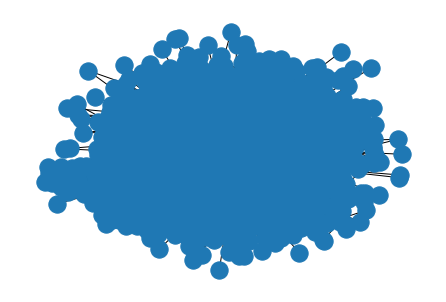

In [67]:
import networkx as nx
import matplotlib.pyplot as plt
import randomcolor
import community

g = nx.from_pandas_edgelist(edges_df, source='source', target='target')
print(len(g.nodes), "nodes")
nx.draw(g)

In [68]:
partition = community.best_partition(g) # Key: node, value: partition id
partition

{'A_01_002': 0,
 'A_01_041': 1,
 'B_02_085': 1,
 'G_01_038': 2,
 'K_02_073': 1,
 'A_01_003': 3,
 'A_03_087': 2,
 'B_03_037': 3,
 'A_01_036': 2,
 'J_03_094': 2,
 'D_02_050': 3,
 'A_01_004': 1,
 'F_03_021': 1,
 'A_01_085': 1,
 'A_01_033': 1,
 'A_02_058': 1,
 'B_03_067': 1,
 'K_03_072': 1,
 'A_01_005': 4,
 'C_01_023': 4,
 'E_01_080': 5,
 'D_02_011': 4,
 'C_01_025': 4,
 'B_02_090': 4,
 'A_01_008': 6,
 'J_01_026': 7,
 'A_03_055': 6,
 'C_01_056': 6,
 'A_02_036': 4,
 'A_01_009': 8,
 'H_02_050': 3,
 'E_02_016': 8,
 'J_01_029': 4,
 'A_01_010': 1,
 'B_02_012': 1,
 'A_02_031': 9,
 'F_02_063': 1,
 'K_02_059': 10,
 'K_02_124': 11,
 'A_01_011': 5,
 'A_02_052': 1,
 'D_01_051': 5,
 'C_02_010': 5,
 'A_01_012': 12,
 'C_02_030': 12,
 'B_03_036': 12,
 'C_01_062': 12,
 'C_02_003': 2,
 'A_01_013': 13,
 'D_03_042': 13,
 'A_01_044': 13,
 'C_02_008': 11,
 'G_03_059': 10,
 'C_01_040': 10,
 'A_01_014': 10,
 'D_01_040': 9,
 'E_03_082': 10,
 'A_03_020': 14,
 'A_01_015': 1,
 'F_01_076': 1,
 'C_01_010': 1,
 'G_02_08

[frozenset({'H_02_071', 'J_01_031', 'G_02_067', 'J_01_046', 'G_03_095', 'G_01_068', 'F_03_059', 'F_03_016', 'C_01_023', 'A_03_059', 'D_01_082', 'B_02_013', 'B_01_060', 'F_03_072', 'H_02_090', 'A_01_080', 'E_03_047', 'G_02_058', 'H_01_025', 'C_03_022', 'A_03_076', 'J_02_075', 'E_02_084', 'A_03_005', 'H_02_029', 'F_02_096', 'K_03_057', 'K_02_042', 'H_01_089', 'C_02_060', 'K_01_035', 'J_02_063', 'F_02_021', 'J_03_040', 'H_03_026', 'G_02_086', 'H_02_049', 'H_03_002', 'B_01_018', 'H_03_075', 'A_03_027', 'G_01_081', 'C_02_078', 'J_02_061', 'H_03_062', 'C_03_057', 'J_01_015', 'C_01_040', 'F_02_033', 'H_02_054', 'D_02_066', 'F_03_026', 'H_02_005', 'B_02_008', 'E_01_073', 'G_01_094', 'H_01_044', 'H_01_071', 'J_02_078', 'H_01_015', 'G_03_017', 'E_03_050', 'D_01_076', 'H_02_062', 'D_02_007', 'C_03_024', 'B_02_027', 'G_02_096', 'F_03_094', 'D_02_028', 'E_03_075', 'C_03_008', 'H_03_071', 'A_03_080', 'B_02_071', 'C_02_085', 'B_03_022', 'D_02_020', 'G_03_034', 'G_03_042', 'H_03_051', 'D_01_075', 'B_0

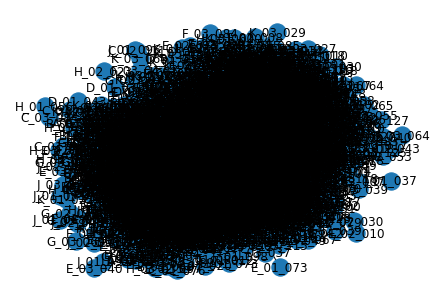

In [80]:
import networkx.algorithms.community as nx_comm
G = nx.from_pandas_edgelist(edges_df, source='source', target='target') 
communities = nx_comm.greedy_modularity_communities(G)
#top_level_communities = next(communities_generator)

#next_level_communities = next(communities_generator)
print(communities)
nx.draw(G, with_labels=True)

In [82]:
nodes_groups_dict = {}
group_id = 0
for comm in communities:
    for node in comm:
        nodes_groups_dict[node] = group_id
    group_id+=1

H_02_071
J_01_031
G_02_067
J_01_046
G_03_095
G_01_068
F_03_059
F_03_016
C_01_023
A_03_059
D_01_082
B_02_013
B_01_060
F_03_072
H_02_090
A_01_080
E_03_047
G_02_058
H_01_025
C_03_022
A_03_076
J_02_075
E_02_084
A_03_005
H_02_029
F_02_096
K_03_057
K_02_042
H_01_089
C_02_060
K_01_035
J_02_063
F_02_021
J_03_040
H_03_026
G_02_086
H_02_049
H_03_002
B_01_018
H_03_075
A_03_027
G_01_081
C_02_078
J_02_061
H_03_062
C_03_057
J_01_015
C_01_040
F_02_033
H_02_054
D_02_066
F_03_026
H_02_005
B_02_008
E_01_073
G_01_094
H_01_044
H_01_071
J_02_078
H_01_015
G_03_017
E_03_050
D_01_076
H_02_062
D_02_007
C_03_024
B_02_027
G_02_096
F_03_094
D_02_028
E_03_075
C_03_008
H_03_071
A_03_080
B_02_071
C_02_085
B_03_022
D_02_020
G_03_034
G_03_042
H_03_051
D_01_075
B_02_086
H_02_022
D_03_015
G_03_083
H_01_045
K_03_016
E_01_010
F_01_095
B_01_005
D_02_059
H_01_056
E_03_103
B_02_005
B_03_073
H_02_063
D_03_083
G_03_093
H_03_036
A_03_075
H_01_091
F_03_038
K_01_042
C_03_044
H_02_042
D_02_035
J_02_087
K_01_005
G_01_043
H_03_030
B

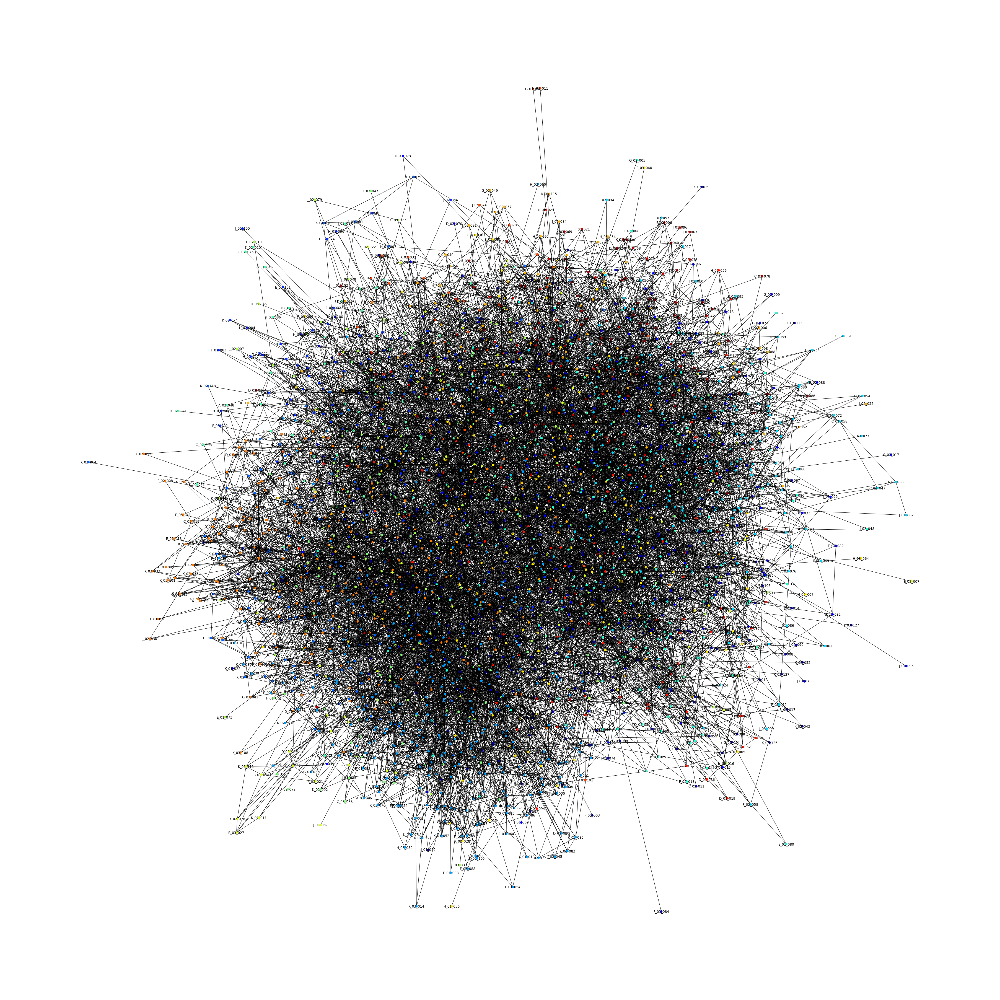

In [58]:
values = [partition.get(node) for node in g.nodes()] 

plt.figure(3,figsize=(50,50)) 
nx.draw_spring(g, cmap = plt.get_cmap('jet'), node_color = values, node_size=60, with_labels=True)
plt.show()

In [65]:
nodes_group_ids = partition.items()

AttributeError: 'generator' object has no attribute 'items'

In [33]:
nodes_with_groupids = pd.DataFrame(nodes_group_ids, columns=['Code', 'group_id'])
nodes_with_groupids

,Code,group_id
0,A_01_002,0
1,A_01_041,0
2,B_02_085,0
3,G_01_038,2
4,K_02_073,0
...,...,...
2702,K_03_118,0
2703,K_03_121,6
2704,K_03_124,19
2705,K_03_125,16


In [34]:
edges_df

,source,target,Number of links
0,A_01_002,A_01_041,2
11,A_01_002,B_02_085,3
13,A_01_002,G_01_038,4
14,A_01_002,B_02_085,4
15,A_01_002,G_01_038,4
...,...,...,...
113758,K_03_124,D_03_070,3
113782,K_03_125,A_02_056,4
113793,K_03_125,G_02_069,2
113794,K_03_125,G_02_069,2


In [35]:
associates_merged = pd.merge(nodes_df, nodes_with_groupids, how='left', on=['Code'])
associates_merged

,EntryID,LemmaID,Code,Batch,List,Item,EnglishWF(lg10),SignFrequency(M),SignFrequency(SD),SignFrequency(Z),...,SignBankAnnotationID,SignBankEnglishTranslations,SignBankLemmaID,SignBankSemanticField,SignBankReferenceID,InCDI,CDISemanticCategory,bglm_aoa,empirical_aoa,group_id
0,tree,tree,A_01_002,A,1,2,3.521,5.143,2.081,0.621,...,TREE,"forest, nature, plant, tree, woods",TREE,None,342.0,Yes,Outside Things and Places to Go,22.0,14.0,0
1,night,night,A_01_003,A,1,3,4.645,6.032,1.516,1.068,...,NIGHT,"night, evening",NIGHT,None,199.0,Yes,Signs About Time,31.0,18.0,2
2,hamburger,hamburger,A_01_004,A,1,4,2.600,4.429,1.720,0.232,...,HAMBURGER,"burger, hamburger, sandwich",HAMBURGER,None,1844.0,Yes,Food and Drink,32.0,28.0,0
3,nephew,nephew,A_01_005,A,1,5,2.928,2.621,1.720,-0.753,...,NEPHEW,nephew,NEPHEW,People,3011.0,No,NaN,NaN,NaN,3
4,castle,castle,A_01_008,A,1,8,3.041,1.579,0.838,-1.198,...,CASTLE,"castle, palace",CASTLE,None,2471.0,No,Action Signs,NaN,NaN,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2702,bored_2,bored_2,K_03_122,K,3,122,3.013,4.458,2.206,0.144,...,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,2
2703,vampire,vampire,K_03_123,K,3,123,2.952,4.480,2.365,0.176,...,VAMPIRE,"bat, fanged, mythical creature, vampire",VAMPIRE,None,1371.0,No,NaN,NaN,NaN,0
2704,blackbird,blackbird,K_03_124,K,3,124,1.633,4.840,2.055,0.356,...,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,19
2705,braids,braids,K_03_125,K,3,125,1.613,3.480,2.163,-0.385,...,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,16


In [36]:
import random
 
    
def colors(n):
    if(n == 0):
        n = 600
    r = int(random.random() * 256)
    g = int(random.random() * 256)
    b = int(random.random() * 256)
    
    step = 256 / n
#     print(n,r,g,b,step)

    r += step
    g += step
    b += step
    r = int(r) % 256
    g = int(g) % 256
    b = int(b) % 256
    
    colorstr = str(r)+","+str(b)+"," + str(g)
    return '#%02x%02x%02x' % (r, g, b)


unique_community_ids = associates_merged['group_id'].unique()

color_dict = []
color_dictionary = {}
for groupid in unique_community_ids:
    #generate a random color
    color = colors(groupid)
    if(groupid == 1000):        
        color_dict.append({'group_id': 1000, 'color_code': color})
        color_dictionary['island'] = color
    else:        
        color_dict.append({'group_id':groupid , 'color_code': color})
        color_dictionary[str(int(groupid))] = color
    
color_dict

[{'group_id': 0, 'color_code': '#11cd79'},
 {'group_id': 2, 'color_code': '#5f7c49'},
 {'group_id': 3, 'color_code': '#9573c8'},
 {'group_id': 20, 'color_code': '#ad9c4e'},
 {'group_id': 7, 'color_code': '#150b18'},
 {'group_id': 4, 'color_code': '#00541c'},
 {'group_id': 18, 'color_code': '#b1131c'},
 {'group_id': 14, 'color_code': '#da0e37'},
 {'group_id': 16, 'color_code': '#236ea0'},
 {'group_id': 19, 'color_code': '#2ea457'},
 {'group_id': 13, 'color_code': '#46aa7a'},
 {'group_id': 8, 'color_code': '#50dac2'},
 {'group_id': 10, 'color_code': '#2cb81b'},
 {'group_id': 6, 'color_code': '#a0bc63'},
 {'group_id': 11, 'color_code': '#3f308c'},
 {'group_id': 17, 'color_code': '#82ebcd'},
 {'group_id': 12, 'color_code': '#d493df'},
 {'group_id': 5, 'color_code': '#f62996'},
 {'group_id': 9, 'color_code': '#60cac6'},
 {'group_id': 1, 'color_code': '#45a847'},
 {'group_id': 15, 'color_code': '#2bfd41'}]

In [37]:
color_df = pd.DataFrame(color_dict)
associates_merged_with_color = pd.merge(associates_merged, color_df,how='left', on=['group_id']) # Now have everything we need with the group ids
                                                                                 # and their colors
associates_merged_with_color

,EntryID,LemmaID,Code,Batch,List,Item,EnglishWF(lg10),SignFrequency(M),SignFrequency(SD),SignFrequency(Z),...,SignBankEnglishTranslations,SignBankLemmaID,SignBankSemanticField,SignBankReferenceID,InCDI,CDISemanticCategory,bglm_aoa,empirical_aoa,group_id,color_code
0,tree,tree,A_01_002,A,1,2,3.521,5.143,2.081,0.621,...,"forest, nature, plant, tree, woods",TREE,None,342.0,Yes,Outside Things and Places to Go,22.0,14.0,0,#11cd79
1,night,night,A_01_003,A,1,3,4.645,6.032,1.516,1.068,...,"night, evening",NIGHT,None,199.0,Yes,Signs About Time,31.0,18.0,2,#5f7c49
2,hamburger,hamburger,A_01_004,A,1,4,2.600,4.429,1.720,0.232,...,"burger, hamburger, sandwich",HAMBURGER,None,1844.0,Yes,Food and Drink,32.0,28.0,0,#11cd79
3,nephew,nephew,A_01_005,A,1,5,2.928,2.621,1.720,-0.753,...,nephew,NEPHEW,People,3011.0,No,NaN,NaN,NaN,3,#9573c8
4,castle,castle,A_01_008,A,1,8,3.041,1.579,0.838,-1.198,...,"castle, palace",CASTLE,None,2471.0,No,Action Signs,NaN,NaN,20,#ad9c4e
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2702,bored_2,bored_2,K_03_122,K,3,122,3.013,4.458,2.206,0.144,...,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,2,#5f7c49
2703,vampire,vampire,K_03_123,K,3,123,2.952,4.480,2.365,0.176,...,"bat, fanged, mythical creature, vampire",VAMPIRE,None,1371.0,No,NaN,NaN,NaN,0,#11cd79
2704,blackbird,blackbird,K_03_124,K,3,124,1.633,4.840,2.055,0.356,...,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,19,#2ea457
2705,braids,braids,K_03_125,K,3,125,1.613,3.480,2.163,-0.385,...,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,16,#236ea0


In [38]:
associates_json_data = associates_merged_with_color[["EntryID", "Code", "group_id", "color_code", "SignFrequency(Z)"]]
associates_json_data

,EntryID,Code,group_id,color_code,SignFrequency(Z)
0,tree,A_01_002,0,#11cd79,0.621
1,night,A_01_003,2,#5f7c49,1.068
2,hamburger,A_01_004,0,#11cd79,0.232
3,nephew,A_01_005,3,#9573c8,-0.753
4,castle,A_01_008,20,#ad9c4e,-1.198
...,...,...,...,...,...
2702,bored_2,K_03_122,2,#5f7c49,0.144
2703,vampire,K_03_123,0,#11cd79,0.176
2704,blackbird,K_03_124,19,#2ea457,0.356
2705,braids,K_03_125,16,#236ea0,-0.385


In [39]:
import json
edges_df = edges_df.fillna('A_01_002')

edges_json_str = edges_df.to_json(orient='records')
edges_json = json.loads(edges_json_str)
edges_json

[{'source': 'A_01_002', 'target': 'A_01_041', 'Number of links': 2},
 {'source': 'A_01_002', 'target': 'B_02_085', 'Number of links': 3},
 {'source': 'A_01_002', 'target': 'G_01_038', 'Number of links': 4},
 {'source': 'A_01_002', 'target': 'B_02_085', 'Number of links': 4},
 {'source': 'A_01_002', 'target': 'G_01_038', 'Number of links': 4},
 {'source': 'A_01_002', 'target': 'K_02_073', 'Number of links': 3},
 {'source': 'A_01_003', 'target': 'A_03_087', 'Number of links': 2},
 {'source': 'A_01_003', 'target': 'B_03_037', 'Number of links': 4},
 {'source': 'A_01_003', 'target': 'A_01_036', 'Number of links': 2},
 {'source': 'A_01_003', 'target': 'J_03_094', 'Number of links': 7},
 {'source': 'A_01_003', 'target': 'D_02_050', 'Number of links': 2},
 {'source': 'A_01_004', 'target': 'F_03_021', 'Number of links': 5},
 {'source': 'A_01_004', 'target': 'A_01_085', 'Number of links': 2},
 {'source': 'A_01_004', 'target': 'A_01_033', 'Number of links': 2},
 {'source': 'A_01_004', 'target': 

In [40]:
nodes_json_str = associates_json_data.to_json(orient="records")
nodes_json = json.loads(nodes_json_str)
nodes_json

[{'EntryID': 'tree',
  'Code': 'A_01_002',
  'group_id': 0,
  'color_code': '#11cd79',
  'SignFrequency(Z)': 0.621},
 {'EntryID': 'night',
  'Code': 'A_01_003',
  'group_id': 2,
  'color_code': '#5f7c49',
  'SignFrequency(Z)': 1.068},
 {'EntryID': 'hamburger',
  'Code': 'A_01_004',
  'group_id': 0,
  'color_code': '#11cd79',
  'SignFrequency(Z)': 0.232},
 {'EntryID': 'nephew',
  'Code': 'A_01_005',
  'group_id': 3,
  'color_code': '#9573c8',
  'SignFrequency(Z)': -0.753},
 {'EntryID': 'castle',
  'Code': 'A_01_008',
  'group_id': 20,
  'color_code': '#ad9c4e',
  'SignFrequency(Z)': -1.198},
 {'EntryID': 'humble',
  'Code': 'A_01_009',
  'group_id': 7,
  'color_code': '#150b18',
  'SignFrequency(Z)': -0.418},
 {'EntryID': 'cup',
  'Code': 'A_01_010',
  'group_id': 0,
  'color_code': '#11cd79',
  'SignFrequency(Z)': 0.909},
 {'EntryID': 'english',
  'Code': 'A_01_011',
  'group_id': 4,
  'color_code': '#00541c',
  'SignFrequency(Z)': 0.326},
 {'EntryID': 'eyeglasses',
  'Code': 'A_01_012

In [41]:
len(edges_json)

19392

In [42]:
graph = {
    "nodes" : nodes_json,
    "links": edges_json
}
with open("new_graph.json", 'w') as file:
    json.dump(graph, file)
    